# Model 3

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.utils import class_weight
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
from pathlib import Path
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras import layers

2026-10-13 23:21:45.683245: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-13 23:21:45.690901: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 23:21:45.700617: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 23:21:45.700637: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-13 23:21:45.707243: I tensorflow/core/platform/cpu_feature_gua

## Data Preparation

In [2]:
DATA_DIR = Path("/home/pc/AAA/project/deepnn/G8_AI66A_DNN/data/raw")
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

In [3]:
training_set = image_dataset_from_directory(
    str(DATA_DIR / "train"),
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)

Found 76515 files belonging to 4 classes.


2026-10-13 23:21:46.875650: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 23:21:46.897809: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
2026-10-13 23:21:46.899723: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:998] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-

In [4]:
validation_set = image_dataset_from_directory(
    str(DATA_DIR / "val"),
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(224, 224),
    shuffle=True,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 21861 files belonging to 4 classes.


In [5]:
training_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 4), dtype=tf.float32, name=None))>

## 2. Data Preprocessing

### 2.1 Class weight

In [6]:
class_names = sorted([d for d in os.listdir(TRAIN_DIR) if os.path.isdir(os.path.join(TRAIN_DIR, d))])

# Đếm số lượng ảnh mỗi lớp
counts = np.array([len(os.listdir(os.path.join(TRAIN_DIR, c))) for c in class_names])

# Tạo mảng nhãn giả để tính toán weight
y_train = np.repeat(np.arange(len(class_names)), counts)

# Tính class weight
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(class_names)),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

print("Class names:", class_names)
print("Counts:", counts)
print("Class weights:", class_weight_dict)

Class names: ['CNV', 'DME', 'DRUSEN', 'NORMAL']
Counts: [26218  8118  6206 35973]
Class weights: {0: 0.7296037073766115, 1: 2.356337767923134, 2: 3.082299387689333, 3: 0.5317529814027188}


### 2.2 Augmentation

In [7]:
INPUT_SHAPE = (224, 224, 3)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")


## 3. Xay dung model

In [8]:
mobnet = tf.keras.applications.MobileNetV3Large(
    input_shape=INPUT_SHAPE,
    alpha=1.0,
    minimalistic=False,
    include_top=False,
    weights="imagenet",
    # classes=1000,
    pooling="avg",      # Thêm GlobalAveragePooling để trả về vector đặc trưng
    include_preprocessing=True,
)

# Đóng băng weight cua pretrained model (Chỉ train phần head mới tạo để giữ vững đặc trưng ImageNet)
mobnet.trainable = False 

In [9]:
model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=INPUT_SHAPE))
model.add(data_augmentation)

model.add(mobnet)
model.add(layers.Dropout(0.3)) 
model.add(layers.Dense(units=4, activation='softmax')) # Head cho 4 lớp bệnh

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

## 4. Compile va Training

In [11]:
metrics_list = ['accuracy', tf.keras.metrics.F1Score(average='macro')]


cb_phase1 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint('Model3_phase1.keras', monitor='val_loss', save_best_only=True),
]

cb_phase2 = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint('Model3_finetuned.keras', monitor='val_loss', save_best_only=True),
]

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=metrics_list
)

In [13]:
history1 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=4,            
    class_weight=class_weight_dict,
    callbacks=cb_phase1
)

Epoch 1/4


/home/pc/miniconda3/envs/pytorch_gpu/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-13 23:21:51.495584: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:465] Loaded cuDNN version 8907


2392/2392 ━━━━━━━━━━━━━━━━━━━━ 71s 28ms/step - accuracy: 0.7229 - f1_score: 0.6372 - loss: 0.9357 - val_accuracy: 0.7473 - val_f1_score: 0.7000 - val_loss: 0.8150
Epoch 2/4
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 66s 28ms/step - accuracy: 0.7642 - f1_score: 0.6816 - loss: 0.8679 - val_accuracy: 0.8286 - val_f1_score: 0.7590 - val_loss: 0.7009
Epoch 3/4
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 62s 26ms/step - accuracy: 0.7666 - f1_score: 0.6834 - loss: 0.8657 - val_accuracy: 0.8078 - val_f1_score: 0.7450 - val_loss: 0.7346
Epoch 4/4
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 66s 28ms/step - accuracy: 0.7647 - f1_score: 0.6824 - loss: 0.8663 - val_accuracy: 0.7648 - val_f1_score: 0.6990 - val_loss: 0.8229


In [ ]:
# Mở khóa toàn bộ backbone
base = model.get_layer("MobileNetV3Large")
base.trainable = True

# Compile lại sau khi đổi trainable
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5, weight_decay=1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=metrics_list
)
model.summary()

history2 = model.fit(
    training_set,
    validation_data=validation_set,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=cb_phase2
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 2,975,796 (11.35 MB)

 Non-trainable params: 24,400 (95.31 KB)

Epoch 1/30
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 230s 91ms/step - accuracy: 0.8361 - f1_score: 0.7496 - loss: 0.7449 - val_accuracy: 0.8345 - val_f1_score: 0.7832 - val_loss: 0.6980 - learning_rate: 3.0000e-05
Epoch 2/30
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 211s 88ms/step - accuracy: 0.9253 - f1_score: 0.8820 - loss: 0.5438 - val_accuracy: 0.8949 - val_f1_score: 0.8495 - val_loss: 0.5754 - learning_rate: 3.0000e-05
Epoch 3/30
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 213s 89ms/step - accuracy: 0.9373 - f1_score: 0.9000 - loss: 0.5044 - val_accuracy: 0.9365 - val_f1_score: 0.9007 - val_loss: 0.4910 - learning_rate: 3.0000e-05
Epoch 4/30
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 213s 89ms/step - accuracy: 0.9454 - f1_score: 0.9119 - loss: 0.4836 - val_accuracy: 0.9439 - val_f1_score: 0.9110 - val_loss: 0.4684 - learning_rate: 3.0000e-05
Epoch 5/30
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 214s 89ms/step - accuracy: 0.9497 - f1_score: 0.9187 - loss: 0.4686 - val_accuracy: 0.9444 - val_f1_score: 0.9122 - val_loss: 0.4675 - learning_ra

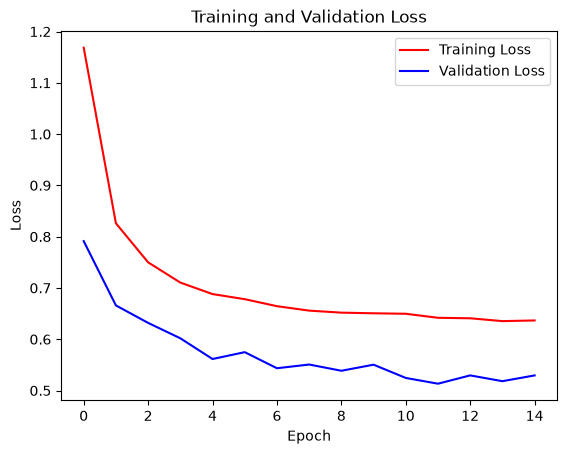

In [ ]:
loss     = history1.history["loss"]     + history2.history["loss"]
val_loss = history1.history["val_loss"] + history2.history["val_loss"]

plt.plot(loss, color="red", label="Training Loss")
plt.plot(val_loss, color="blue", label="Validation Loss")
plt.axvline(len(history1.history["loss"]) - 1, ls="--", color="gray", label="Bắt đầu fine-tune")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend(); plt.show()

In [ ]:
model.save("Model3.keras")

## 5. Danh gia tren tap test

In [ ]:
test_set = image_dataset_from_directory(
    str(DATA_DIR / "test"),
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=64,
    image_size=(224, 224),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 10933 files belonging to 4 classes.


In [ ]:
test_loss,test_acc,f1_score = model.evaluate(test_set)

171/171 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.7984 - f1_score: 0.7315 - loss: 0.5322


In [ ]:
test_loss

0.5321710705757141

In [ ]:
test_acc

0.7984085083007812

In [ ]:
f1_score

0.731485903263092

In [ ]:
model.save("Trained_Model.keras")

### 5.1 Model Evaluation

In [ ]:
model = tf.keras.models.load_model("Model3.keras")


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 960)            │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,007,886 (11.47 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

 Optimizer params: 7,690 (30.04 KB)

In [ ]:
test_set = image_dataset_from_directory(
    str(TEST_DIR),
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=64,
    image_size=(224, 224),
    shuffle=False,
    seed=None,
    validation_split=None,
    subset=None,
    interpolation="bilinear",
    follow_links=False,
    crop_to_aspect_ratio=False
)


Found 10933 files belonging to 4 classes.


In [ ]:
##Computing True labels from test set
true_categories = tf.concat([y for x, y in test_set], axis=0)
Y_true = tf.argmax(true_categories, axis=1)

2026-10-13 23:00:09.312169: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [ ]:
##Computing Predicted labels using test set
predicted_categories = model.predict(test_set)
Y_pred = tf.argmax(predicted_categories, axis=1)

171/171 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step


In [ ]:
Y_true

<tf.Tensor: shape=(10933,), dtype=int64, numpy=array([0, 0, 0, ..., 3, 3, 3])>

In [ ]:
Y_pred

<tf.Tensor: shape=(10933,), dtype=int64, numpy=array([0, 0, 0, ..., 3, 3, 3])>

### 5.2 Classification Report

In [ ]:
from sklearn.metrics import classification_report
print(classification_report(Y_true,Y_pred))

              precision    recall  f1-score   support

           0       0.96      0.72      0.83      3746
           1       0.70      0.78      0.74      1161
           2       0.32      0.81      0.46       887
           3       0.96      0.86      0.90      5139

    accuracy                           0.80     10933
   macro avg       0.74      0.79      0.73     10933
weighted avg       0.88      0.80      0.82     10933



### Confusion Matrix

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_true,Y_pred)
cm

array([[2702,  188,  830,   26],
       [  39,  902,  139,   81],
       [  45,   28,  715,   99],
       [  18,  166,  545, 4410]])

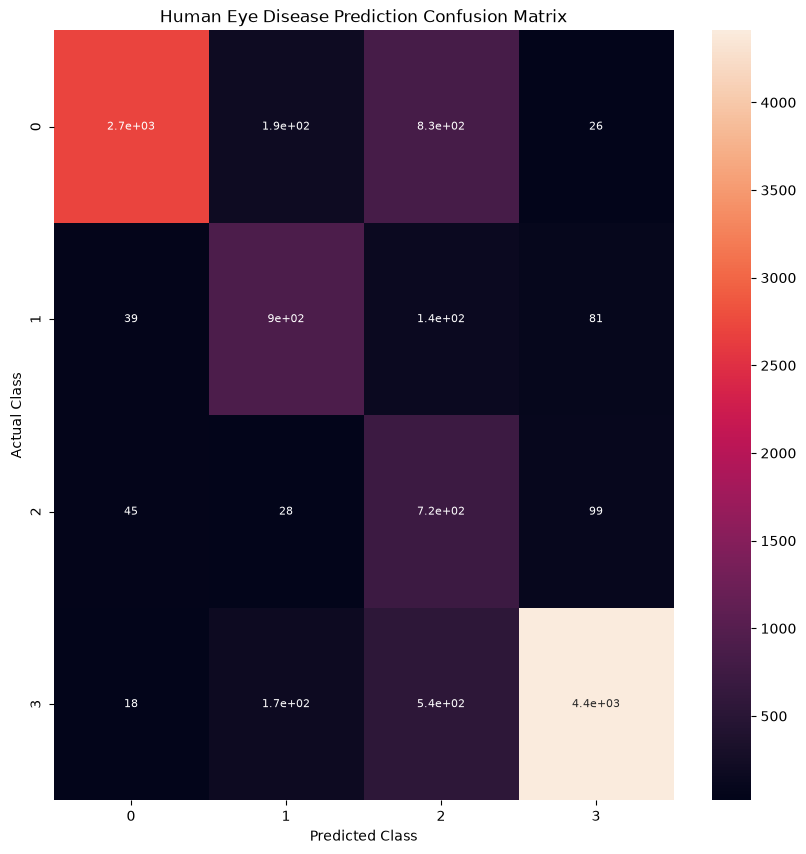

In [ ]:
import seaborn as sns
plt.figure(figsize=(10,10))
sns.heatmap(cm,annot=True,annot_kws={"size":8})
plt.xlabel("Predicted Class",fontsize=10)
plt.ylabel("Actual Class",fontsize=10)
plt.title("Human Eye Disease Prediction Confusion Matrix",fontsize=12)
plt.show()